In [ ]:
from PIL import Image
import os
import glob
import numpy as np
import cv2
import pywt
from skimage import exposure, restoration, morphology, filters
import matplotlib.pyplot as plt
from pathlib import Path
import torchvision as tv
import torch
import ptwt

In [ ]:
# read image file from data/C01 folder

image_files = glob.glob(os.path.join("..", "data", "C01", "*.tif"))
print(f"Found {len(image_files)} image files.")

# show the 100th image
img_path = image_files[99]
img = Image.open(img_path)

# show the dimensions of the image
print(f"Image dimensions: {img.size}")

In [ ]:
# read image file from data/C02 folder

image_files = glob.glob(os.path.join("..", "data", "C02", "*.tif"))
print(f"Found {len(image_files)} image files.")

# show the 100th image
img_path = image_files[99]
img = Image.open(img_path)

# show the dimensions of the image
print(f"Image dimensions: {img.size}")

In [ ]:
# read the image to torch tensor
import torchvision.transforms as transforms

transform = transforms.ToTensor()
img_tensor = transform(img)
print(f"Image tensor shape: {img_tensor.shape}")

print(img_tensor.min())

print(img_tensor.max())

# Preprocessing Image Data

In [ ]:
image = img_tensor.squeeze().numpy()
decomposition_level = 3
# Conceptual logic for destriping
coeffs = pywt.wavedec2(image, "db10", level=decomposition_level)

In [ ]:
"""
Virtual H&E Staining Pipeline
CS-leaning Title: Physics-Based Beer-Lambert Mapping for Fluorescence to Brightfield Image Translation

This script implements the Physics-Based Beer-Lambert Mapping.
It translates two-channel fluorescence images (TO-PRO-3 and Eusion) into a Virtual H&E brightfield image.
The implementation assumes 2D images are not connected in 3D stacks and treats them individually.
"""


# Defining the Color Vectors (Ruifrok and Johnston)
# Absorption values for [Red, Green, Blue]
# Hematoxylin absorbs Red/Green, transmits Blue/Purple
V_H = np.array([0.644, 0.717, 0.267])
# Eosin absorbs Green, transmits Pink/Red
V_E = np.array([0.093, 0.954, 0.283])

# Default gain factors (k_nuc, k_cyto) - represent "staining time"
k_H = 1.0  # Adjustable scaling for Hematoxylin
k_E = 1.0  # Adjustable scaling for Eosin

In [ ]:
def beer_lambert_mapping(nuc_img, cyto_img):
    """
    Color Mapping Algorithm via Beer-Lambert Law
    """
    H, W = nuc_img.shape

    # 1. Calculate Optical Density (OD)
    # OD_c = (N * k_H * V_H_c) + (C * k_E * V_E_c)

    # Initialize Optical Density stack
    OD = np.zeros((H, W, 3), dtype=np.float32)

    # Calculate OD for each channel (R, G, B)
    # nuc_img and cyto_img are already normalized 0.0-1.0 representing concentration
    for i in range(3):  # Loop R, G, B
        OD[:, :, i] = (nuc_img * k_H * V_H[i]) + (cyto_img * k_E * V_E[i])

    # 2. Calculate Transmission
    # I = I0 * exp(-OD)
    # I0 is 255 for 8-bit image
    transmission = 255.0 * np.exp(-OD)

    # Clip to valid range
    transmission = np.clip(transmission, 0, 255).astype(np.uint8)

    return transmission

In [ ]:
def post_process(image):
    """
    Color Balancing & Sharpening
    """
    img_float = image.astype(np.float32)

    # 1. Warmth Adjustment
    # "R * 1.05, B * 0.95" to mimic tungsten-halogen
    img_float[:, :, 0] *= 1.05  # R
    img_float[:, :, 2] *= 0.95  # B
    img_float = np.clip(img_float, 0, 255)

    # 2. Sharpening
    # "Unsharp Mask (radius 1.0, amount 0.5)" applied to luminance
    # Convert to YUV or HSV to get luminance, sharpen, then convert back
    # Ideally, we just sharpen the image directly for simplicity as per standard PIL/skimage flows

    # Using skimage unsharp mask
    img_sharp = filters.unsharp_mask(img_float / 255.0, radius=1.0, amount=0.5)
    img_sharp = (img_sharp * 255).astype(np.uint8)

    return img_sharp

In [ ]:
# Function to apply FFT damping
def fft_damp(detail_coeff, sigma=10):
    rows, cols = detail_coeff.shape
    # Transform to Fourier Domain
    f_transform = np.fft.fftshift(np.fft.fft2(detail_coeff))

    # Create Gaussian Mask
    # We want to suppress high frequencies along the specific axis causing stripes
    cy, cx = rows // 2, cols // 2
    y = np.arange(rows)
    x = np.arange(cols)
    X, Y = np.meshgrid(x, y)

    # Gaussian damping mask centered at DC (0 frequency)
    # This preserves structure (center) but damps specific high-freq stripes
    mask = 1 - np.exp(-((X - cx) ** 2 + (Y - cy) ** 2) / (2 * sigma**2))

    # Apply mask
    f_filtered = f_transform * mask

    # Inverse FFT
    return np.real(np.fft.ifft2(np.fft.ifftshift(f_filtered)))


def destripe_channel(image, wavelet="db2", level=None, sigma=10):
    """
    Removes directional stripe artifacts common in Light-Sheet Microscopy.
    """
    if level is None:
        level = pywt.dwt_max_level(min(image.shape), pywt.Wavelet(wavelet))

    # 1. Decomposition
    coeffs = pywt.wavedec2(image, wavelet, level=level)

    # Parse coefficients: [cAn, (cHn, cVn, cDn), ..., (cH1, cV1, cD1)]
    coeffs_list = list(coeffs)

    # 2. Filtering Detail Coefficients
    for i in range(1, len(coeffs_list)):
        (cH, cV, cD) = coeffs_list[i]

        # We filter cV (Vertical Detail) and cH (Horizontal Detail) to be robust
        # against both stripe orientations.
        cV_filtered = fft_damp(cV, sigma)
        cH_filtered = fft_damp(cH, sigma)

        coeffs_list[i] = (cH_filtered, cV_filtered, cD)

    # 3. Reconstruction
    destriped_image = pywt.waverec2(coeffs_list, wavelet)

    # Clip to original range
    destriped_image = np.clip(destriped_image, 0, np.max(image))
    return destriped_image


def preprocess_channel(image, is_nuclear=True):
    """
    Destriping, CLAHE, Normalization
    """
    img = image.astype(np.float32)

    # 1. Destriping
    # Only destripe if image has significant dimensions
    if min(img.shape) > 64:
        img = destripe_channel(img)

    # 2. Background Subtraction
    # Estimate background using morphological opening (structural element size depends on resolution)
    # Using a disk of radius 50 as a generic estimator for background
    background = (
        restoration.rolling_ball(img, radius=50)
        if hasattr(restoration, "rolling_ball")
        else filters.gaussian(img, sigma=50)
    )
    img = img - background
    img = np.maximum(img, 0)  # Clip negatives

    # 3. CLAHE
    # Contrast Limited Adaptive Histogram Equalization
    # "Clip limit 0.01 is strictly enforced"
    # Rescale to 0-1 for CLAHE
    img_norm = (img - img.min()) / (img.max() - img.min() + 1e-8)
    img_clahe = exposure.equalize_adapthist(
        img_norm, clip_limit=0.01, kernel_size=(64, 64)
    )

    # 4. Handling "Eusion" Noise Floor
    if not is_nuclear:
        # "Pixels below a certain noise floor are aggressively damped"
        # Soft thresholding
        noise_floor = np.percentile(img_clahe, 10)  # Assume bottom 10% is noise
        img_clahe = np.maximum(img_clahe - noise_floor, 0)

    # 5. Percentile Scaling / Normalization
    # Rescaled such that the 99.9th percentile maps to 1.0
    p99_9 = np.percentile(img_clahe, 99.9)
    if p99_9 > 0:
        img_final = img_clahe / p99_9
    else:
        img_final = img_clahe

    return np.clip(img_final, 0, 1.0)

In [ ]:
def process_image_pair(to_pro_3_path: str, eusion_path: str, output_path=None):
    print(f"Loading images...\nNuclear: {to_pro_3_path}\nCytoplasmic: {eusion_path}")

    nuc_raw = cv2.imread(to_pro_3_path, cv2.IMREAD_GRAYSCALE)
    cyto_raw = cv2.imread(eusion_path, cv2.IMREAD_GRAYSCALE)

    if nuc_raw is None or cyto_raw is None:
        raise FileNotFoundError("Could not load one or both input images.")

    print("Preprocessing Nuclear Channel (TO-PRO-3)...")
    nuc_processed = preprocess_channel(nuc_raw, is_nuclear=True)

    print("Preprocessing Cytoplasmic Channel (Eusion)...")
    cyto_processed = preprocess_channel(cyto_raw, is_nuclear=False)

    print("Applying Beer-Lambert Color Mapping...")
    virtual_he = beer_lambert_mapping(nuc_processed, cyto_processed)

    print("Post-processing...")
    final_he = post_process(virtual_he)

    # Convert RGB to BGR for OpenCV saving
    final_bgr = cv2.cvtColor(final_he, cv2.COLOR_RGB2BGR)

    if output_path:
        cv2.imwrite(output_path, final_bgr)
        print(f"Saved Virtual H&E to {output_path}")

    return final_he

In [ ]:
nuc_image_dir = Path("../data/C01/")
cyto_image_dir = Path("../data/C02/")
output_dir = Path("../data/virtual_he/")

output_dir.mkdir(parents=True, exist_ok=True)

try:
    nuc_path = list(nuc_image_dir.glob("*0252.tif"))[0]
    cyto_path = cyto_image_dir / nuc_path.name
    output_path = output_dir / nuc_path.name

    if not cyto_path.exists():
        print(f"Skipping {nuc_path.name}: Corresponding cytoplasmic image not found.")

    result = process_image_pair(str(nuc_path), str(cyto_path), str(output_path))

    # Optional: Show result using matplotlib
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 3, 1)
    plt.title("Nuclear Input")
    plt.imshow(cv2.imread(str(nuc_path), cv2.IMREAD_GRAYSCALE), cmap="gray")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.title("Cytoplasmic Input")
    plt.imshow(cv2.imread(str(cyto_path), cv2.IMREAD_GRAYSCALE), cmap="gray")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.title("Virtual H&E Output")
    plt.imshow(result)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Error: {e}")

In [ ]:
import einops as eo
import pywt

torch.set_printoptions(threshold=10000)

wavelet = pywt.Wavelet("db2")
level = 5

print(image.shape)
print(eo.rearrange(image, "h w -> 1 1 h w").shape)


coeff_list = pywt.wavedec2(image, wavelet, level=level)

image_torch = torch.from_numpy(image).to("cuda").double()

coeffs_list = ptwt.wavedec2(image_torch, wavelet, mode="symmetric", level=level)

In [ ]:
coeffs_list

In [ ]:
repr(coeff_list[0][0][0].item())

In [1]:
from PIL import Image
import os
import glob
import numpy as np
import cv2
import pywt
from skimage import exposure, restoration, morphology, filters
import matplotlib.pyplot as plt
from pathlib import Path
import torchvision as tv
import torch
import ptwt
import tifffile as tiff

In [2]:
image_files = glob.glob(os.path.join("..", "data", "C02", "*.tif"))
print(f"Found {len(image_files)} image files.")

# show the 100th image
img_path = image_files[156]
image = tiff.imread(img_path)
image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
print(type(image))
print(image.dtype)

Found 256 image files.
<class 'numpy.ndarray'>
uint8


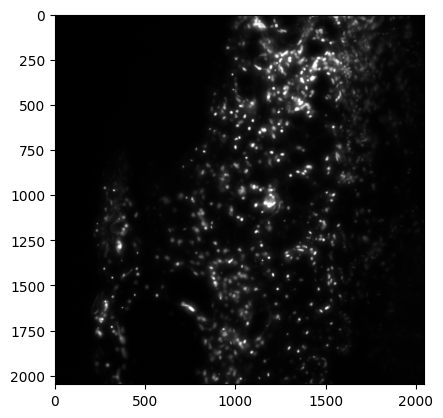

In [3]:
plt.imshow(image, cmap="gray")

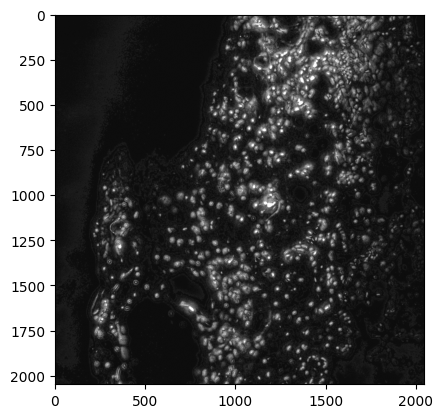

In [4]:
# opencv clahe

clahe = cv2.createCLAHE(clipLimit=0.01 * 255, tileGridSize=(512, 512))
img_clahe = clahe.apply(image)
plt.imshow(img_clahe, cmap="gray")

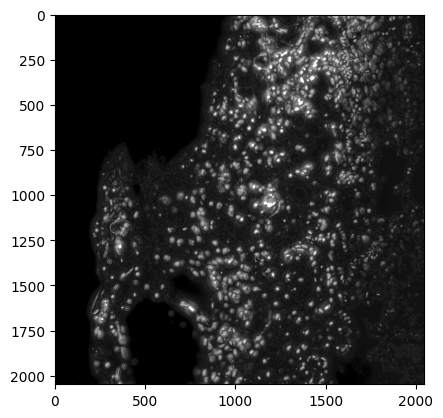

In [5]:
img_norm = (image - image.min()) / (image.max() - image.min() + 1e-8)
image_clahe_scikit = exposure.equalize_adapthist(
    img_norm, clip_limit=0.01, kernel_size=(4, 4)
)
plt.imshow(image_clahe_scikit, cmap="gray")

In [6]:
from kornia.enhance import equalize_clahe
import einops as eo

image_torch = torch.from_numpy(image).to("cuda").float()
img_norm_torch = image_torch / 255.0
img_norm_torch = eo.rearrange(img_norm_torch, "h w -> 1 h w")

In [7]:
kornia_clahe = equalize_clahe(img_norm_torch, clip_limit=0.01, grid_size=(256, 256))

False

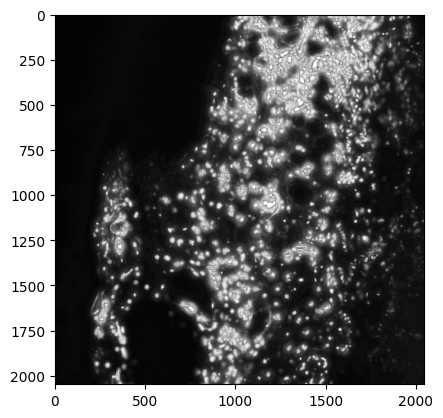

In [8]:
img_clahe_kornia = kornia_clahe.squeeze().cpu().numpy()
plt.imshow(img_clahe_kornia, cmap="gray")
np.allclose(img_clahe_kornia, image_clahe_scikit, atol=1e-2)

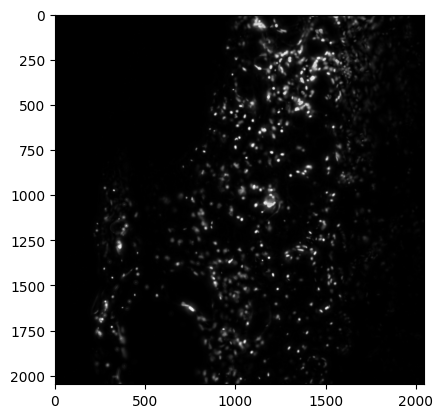

In [9]:
background = restoration.rolling_ball(image, radius=50)
image1 = image - background
image2 = np.maximum(image1, 0)
plt.imshow(image2, cmap="gray")

In [10]:
import kornia as K


def rolling_ball_pytorch(img_tensor: torch.Tensor, radius=10):
    """
    Applies rolling ball background subtraction using Kornia.

    Args:
        img_tensor (torch.Tensor): Input image [B, C, H, W], normalized 0-1.
        radius (int): Radius of the rolling ball.

    Returns:
        torch.Tensor: The background-subtracted image (Top-Hat transform).
    """
    # 1. Create the non-flat "Ball" kernel (structuring element)
    # The kernel represents the height of the ball at each pixel.
    device = img_tensor.device
    dtype = img_tensor.dtype

    if img_tensor.max() <= 1.0:
        height_scale = 1.0 / 255.0
    else:
        height_scale = 1.0

    kernel_size = 2 * radius + 1
    X, Y = torch.meshgrid(
        torch.linspace(-radius, radius, kernel_size, device=device),
        torch.linspace(-radius, radius, kernel_size, device=device),
        indexing="ij",
    )

    # Calculate height of the ball: z = sqrt(r^2 - x^2 - y^2)
    # Pixels outside the ball radius should be -infinity (masked out)
    dist_squared = X**2 + Y**2
    valid_mask = dist_squared <= radius**2

    # Initialize kernel with -inf (for erosion) or similar logic.
    # Kornia expects the structuring element relative values.
    # For a ball, the values are the height offsets.
    ball_height = torch.sqrt(torch.clamp(radius**2 - dist_squared, min=0))
    scaled_ball_height = ball_height * height_scale

    # Normalize height to match image scale if necessary, usually kept relative.
    # However, for standard "rolling ball", we often just need the shape.
    # If strictly mimicking 2D flat rolling ball (ImageJ default), use a flat disk:
    # kernel = torch.from_numpy(valid_mask.astype(np.float32)).to(img_tensor.device)

    # EXACT PARITY with skimage "ball" kernel (non-flat):
    kernel = ball_height

    # Mask out values outside the circle to avoid square artifacts
    kernel = torch.where(
        valid_mask,
        scaled_ball_height,
        torch.tensor(-float("inf"), device=device, dtype=dtype),
    )

    # 2. Apply Top Hat Transform
    # TopHat(I) = Image - Opening(Image)
    # Opening(I) = Dilation(Erosion(I))

    # Kornia's top_hat performs this automatically
    # Note: 'engine="convolution"' is faster but 'unfold' is more stable for non-flat
    result = K.morphology.top_hat(
        eo.rearrange(img_tensor.float(), "h w -> 1 1 h w"),
        kernel=kernel,
        engine="unfold",
    )

    return result


image_torch_balled = rolling_ball_pytorch(image_torch, radius=2)

print(
    torch.allclose(
        image_torch_balled.squeeze(), torch.from_numpy(image1).to("cuda").float()
    )
)
print(
    torch.allclose(
        image_torch_balled.squeeze(), torch.from_numpy(image2).to("cuda").float()
    )
)
print(
    torch.allclose(
        image_torch_balled.squeeze(), torch.from_numpy(image).to("cuda").float()
    )
)

False
False
False
